This script runs analyses on the data used in Bräcklein et al. 2022 experiments

### imports

In [ ]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
from sklearn.pipeline import make_pipeline
from scipy.stats import mannwhitneyu
from scipy.interpolate import interp1d
from scipy import stats



## Load all sessions

In [4]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_13.pkl',
         'E3_MB07_Day09High_18.pkl', 
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
         'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
         'E3_MB07_Day09High_4.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


## Scale experimental forces to use them as inputs to the model 

In [31]:
# s1_trials = [21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28]

# compute_representative_trial(
#     directory_path="/Users/nmt121/Desktop/DATA/S1",
#     save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/",
#     file_prefix="force_S111111",
#     target_max=.8,
#     trial_numbers_by_day=[21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28],
#     plot=True
# )


Day01 trial 01: peak=0.1756 → scale=2.56289  -> Day01_trial01.npy
Day01 trial 06: peak=0.1904 → scale=2.36327  -> Day01_trial06.npy
Day01 trial 09: peak=0.1279 → scale=3.51941  -> Day01_trial09.npy
Day01 trial 11: peak=0.1351 → scale=3.33161  -> Day01_trial11.npy
Day01 trial 14: peak=0.1495 → scale=3.00988  -> Day01_trial14.npy
Day01 trial 17: peak=0.1230 → scale=3.65959  -> Day01_trial17.npy
Day01 trial 21: peak=0.1400 → scale=3.21507  -> Day01_trial21.npy
Day01 trial 24: peak=0.1283 → scale=3.50656  -> Day01_trial24.npy
Day01 trial 27: peak=0.1247 → scale=3.60894  -> Day01_trial27.npy
Day01 trial 30: peak=0.1221 → scale=3.68611  -> Day01_trial30.npy
Day03 trial 03: peak=0.2124 → scale=2.11854  -> Day03_trial03.npy
Day03 trial 04: peak=0.1283 → scale=3.50653  -> Day03_trial04.npy
Day03 trial 09: peak=0.1923 → scale=2.33997  -> Day03_trial09.npy
Day03 trial 11: peak=0.2324 → scale=1.93652  -> Day03_trial11.npy
Day03 trial 14: peak=0.1325 → scale=3.39698  -> Day03_trial14.npy
Day03 tria

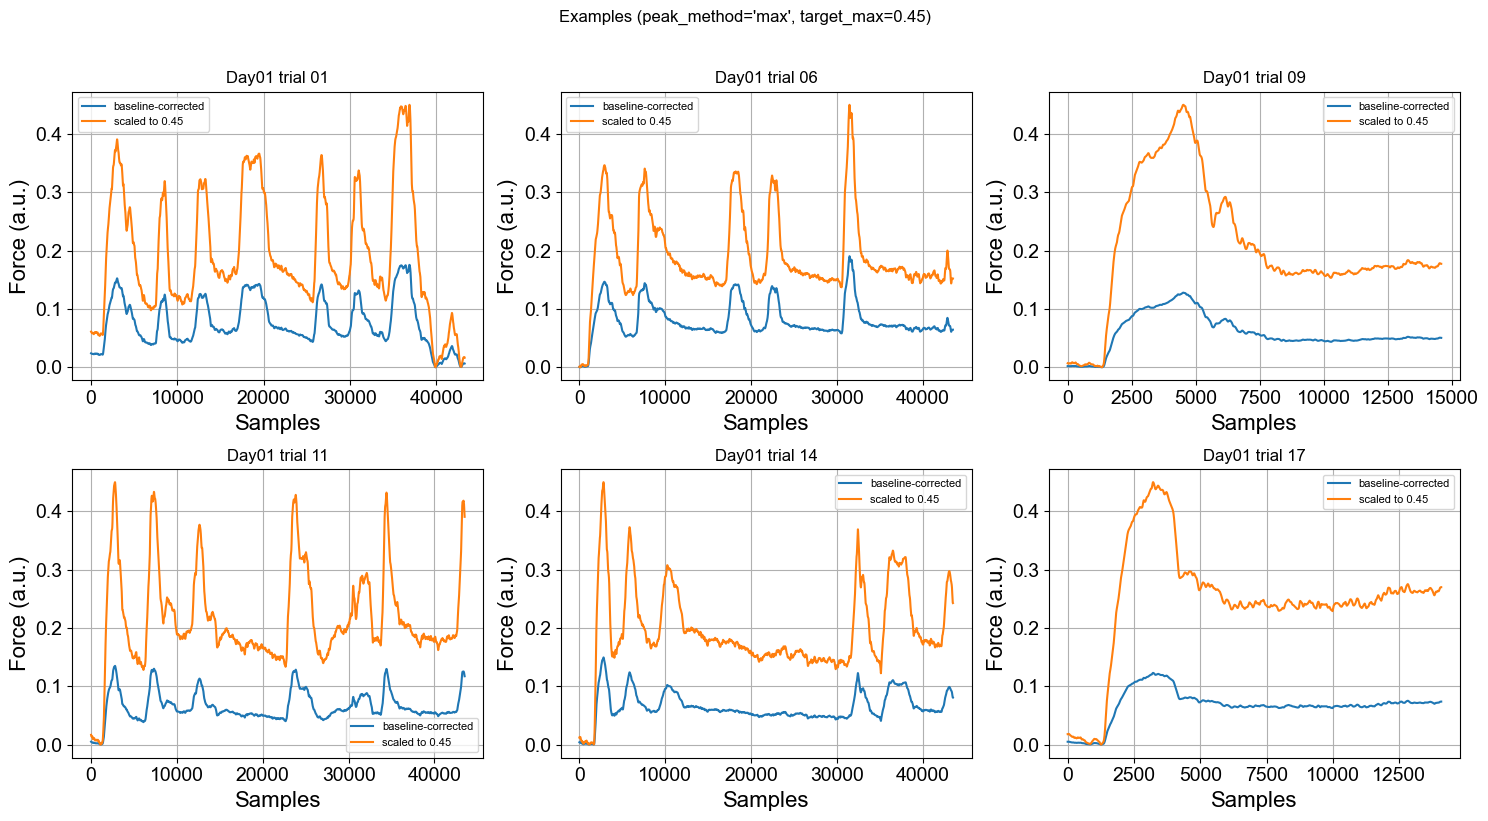


Saved 130 scaled trials to: /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1_alltrials/


In [ ]:
import os, re, pickle, numpy as np
from typing import Literal, Optional
import matplotlib.pyplot as plt

# --- helpers (same behavior as yours) ---
def extract_day(filename):
    m = re.search(r"(Day\d{2})", filename)
    return m.group(1) if m else None

def extract_trial(filename):
    m = re.search(r'_(\d+)[^0-9]', filename)
    return int(m.group(1)) if m else 0

def _safe_force_from_pickle(data):
    # your files sometimes have list-wrapped arrays
    try:
        x = np.array(data['Force']).squeeze()
        if x.ndim > 1:
            x = np.array(data['Force'].tolist())[0].squeeze()
    except Exception:
        x = np.array(data['Force'].tolist())[0].squeeze()
    return np.asarray(x, float)

def scale_and_save_all_trials(
    directory_path: str,
    save_dir: str,
    target_max: float = 0.45,
    peak_method: Literal["max","p99"] = "max",
    plot_examples: bool = True,
    n_examples: int = 6,
    overwrite: bool = True,
    verbose: bool = True,
):
    """
    For every *.pkl in directory_path:
      1) load Force
      2) baseline-correct per trial (subtract min)
      3) scale so chosen peak == target_max (per trial)
      4) save as .npy to save_dir: <Subject>_<Day>_trial<NN>.npy (keeps original length)

    Notes:
      - 'max' uses exact max; 'p99' uses 99th percentile to be robust to spikes.
      - If a trial is flat (no dynamic range), it will be saved as zeros.
      - Also writes a manifest .csv with (day, trial, src_file, out_file, scale_factor, peak_value).
    """
    os.makedirs(save_dir, exist_ok=True)

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    if len(pkl_files) == 0:
        raise FileNotFoundError(f"No .pkl files found in {directory_path}")

    # group by day just for nice ordering
    files_by_day = {}
    for f in pkl_files:
        day = extract_day(f)
        if day is not None:
            files_by_day.setdefault(day, []).append(f)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    manifest_rows = []
    ex_plots = []

    for day in session_days:
        for fname in files_by_day[day]:
            trial = extract_trial(fname)
            src_path = os.path.join(directory_path, fname)

            # load force
            with open(src_path, "rb") as f:
                data = pickle.load(f)
            force = _safe_force_from_pickle(data)

            # baseline-correct and handle NaNs
            f0 = np.asarray(force, float)
            if np.any(~np.isfinite(f0)):
                f0 = np.nan_to_num(f0, nan=np.nanmedian(f0[np.isfinite(f0)]))
            f0 = f0 - np.min(f0)  # now min==0

            # choose the peak measure
            if peak_method == "max":
                peak_val = float(np.max(f0)) if f0.size else 0.0
            else:  # p99
                peak_val = float(np.percentile(f0, 99)) if f0.size else 0.0

            if peak_val <= 0:
                scaled = np.zeros_like(f0)
                scale_factor = 0.0
            else:
                scale_factor = target_max / peak_val
                scaled = f0 * scale_factor
                # hard clip tiny overshoots due to float
                scaled = np.clip(scaled, 0.0, target_max)

            out_name = f"{day}_trial{trial:02d}.npy"
            out_path = os.path.join(save_dir, out_name)

            if overwrite or (not os.path.exists(out_path)):
                np.save(out_path, scaled)

            if verbose:
                print(f"{day} trial {trial:02d}: peak={peak_val:.4f} → scale={scale_factor:.5f}  -> {out_name}")

            manifest_rows.append([day, trial, fname, out_name, f"{scale_factor:.8f}", f"{peak_val:.8f}"])

            # store a few examples to plot
            if plot_examples and len(ex_plots) < n_examples:
                ex_plots.append((day, trial, f0, scaled))



    if plot_examples and ex_plots:
        cols = 3
        rows = int(np.ceil(len(ex_plots) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), sharex=False, sharey=False)
        axes = np.atleast_1d(axes).ravel()
        for i, (day, trial, raw, scaled) in enumerate(ex_plots):
            ax = axes[i]
            ax.plot(raw, label="baseline-corrected")
            ax.plot(scaled, label=f"scaled to {target_max}")
            ax.set_title(f"{day} trial {trial:02d}")
            ax.set_xlabel("Samples")
            ax.set_ylabel("Force (a.u.)")
            ax.legend(fontsize=8)
            ax.grid(True)
        # remove unused axes
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])
        fig.suptitle(f"Examples (peak_method='{peak_method}', target_max={target_max})", y=1.02)
        plt.tight_layout()
        plt.show()





scale_and_save_all_trials(
    directory_path="/Users/nmt121/Desktop/DATA/S1",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1_alltrials/",
    target_max=0.45,         # every trial ends in [0, 0.45]
    peak_method="max",       # or "p99" if you want robustness to spikes
    plot_examples=True,      # quick sanity check plots
    n_examples=6,
    overwrite=True,
    verbose=True
)


[16.74115338 17.42241276 17.37445613 17.45857867 17.20779141 17.26262666
 17.46840274 16.8462378  17.38952037 17.01004472 16.67163719 16.65474709
 16.50561044 16.80196153 16.79659955 16.8905313  16.83847788 16.8519648
 16.79691601 16.88259258 17.09326359 16.59730722 16.68219921 17.67221228
 16.82225624 17.22248317 16.4369891  17.52269262 17.33560557 16.71109891
 16.73320808 16.02705053 16.26361712 17.4434985  16.60702345 17.19459445
 16.59105258 16.10779    15.90482552 16.36436684 16.60699545 17.02864776
 17.27445338 16.03978649 15.48450325 15.63629967 16.8789583  15.66427542
 16.97066325 15.84359826 17.30116526 17.30706059 16.73775318 16.86543199
 17.4204519  17.71886717 16.96203584 15.07295457 17.24032375 16.08923904
 15.17688414 14.5640894  14.89118831 14.72150179 17.4025263  14.14632824
 18.1871072  14.11056566 17.88628245 13.86471504 16.66192945 13.84120676
 13.9282301  14.95431579 16.30758156 14.58235975 13.74734173 13.18385028
 15.25205118 14.47392471 13.46891712 16.40379785 13.

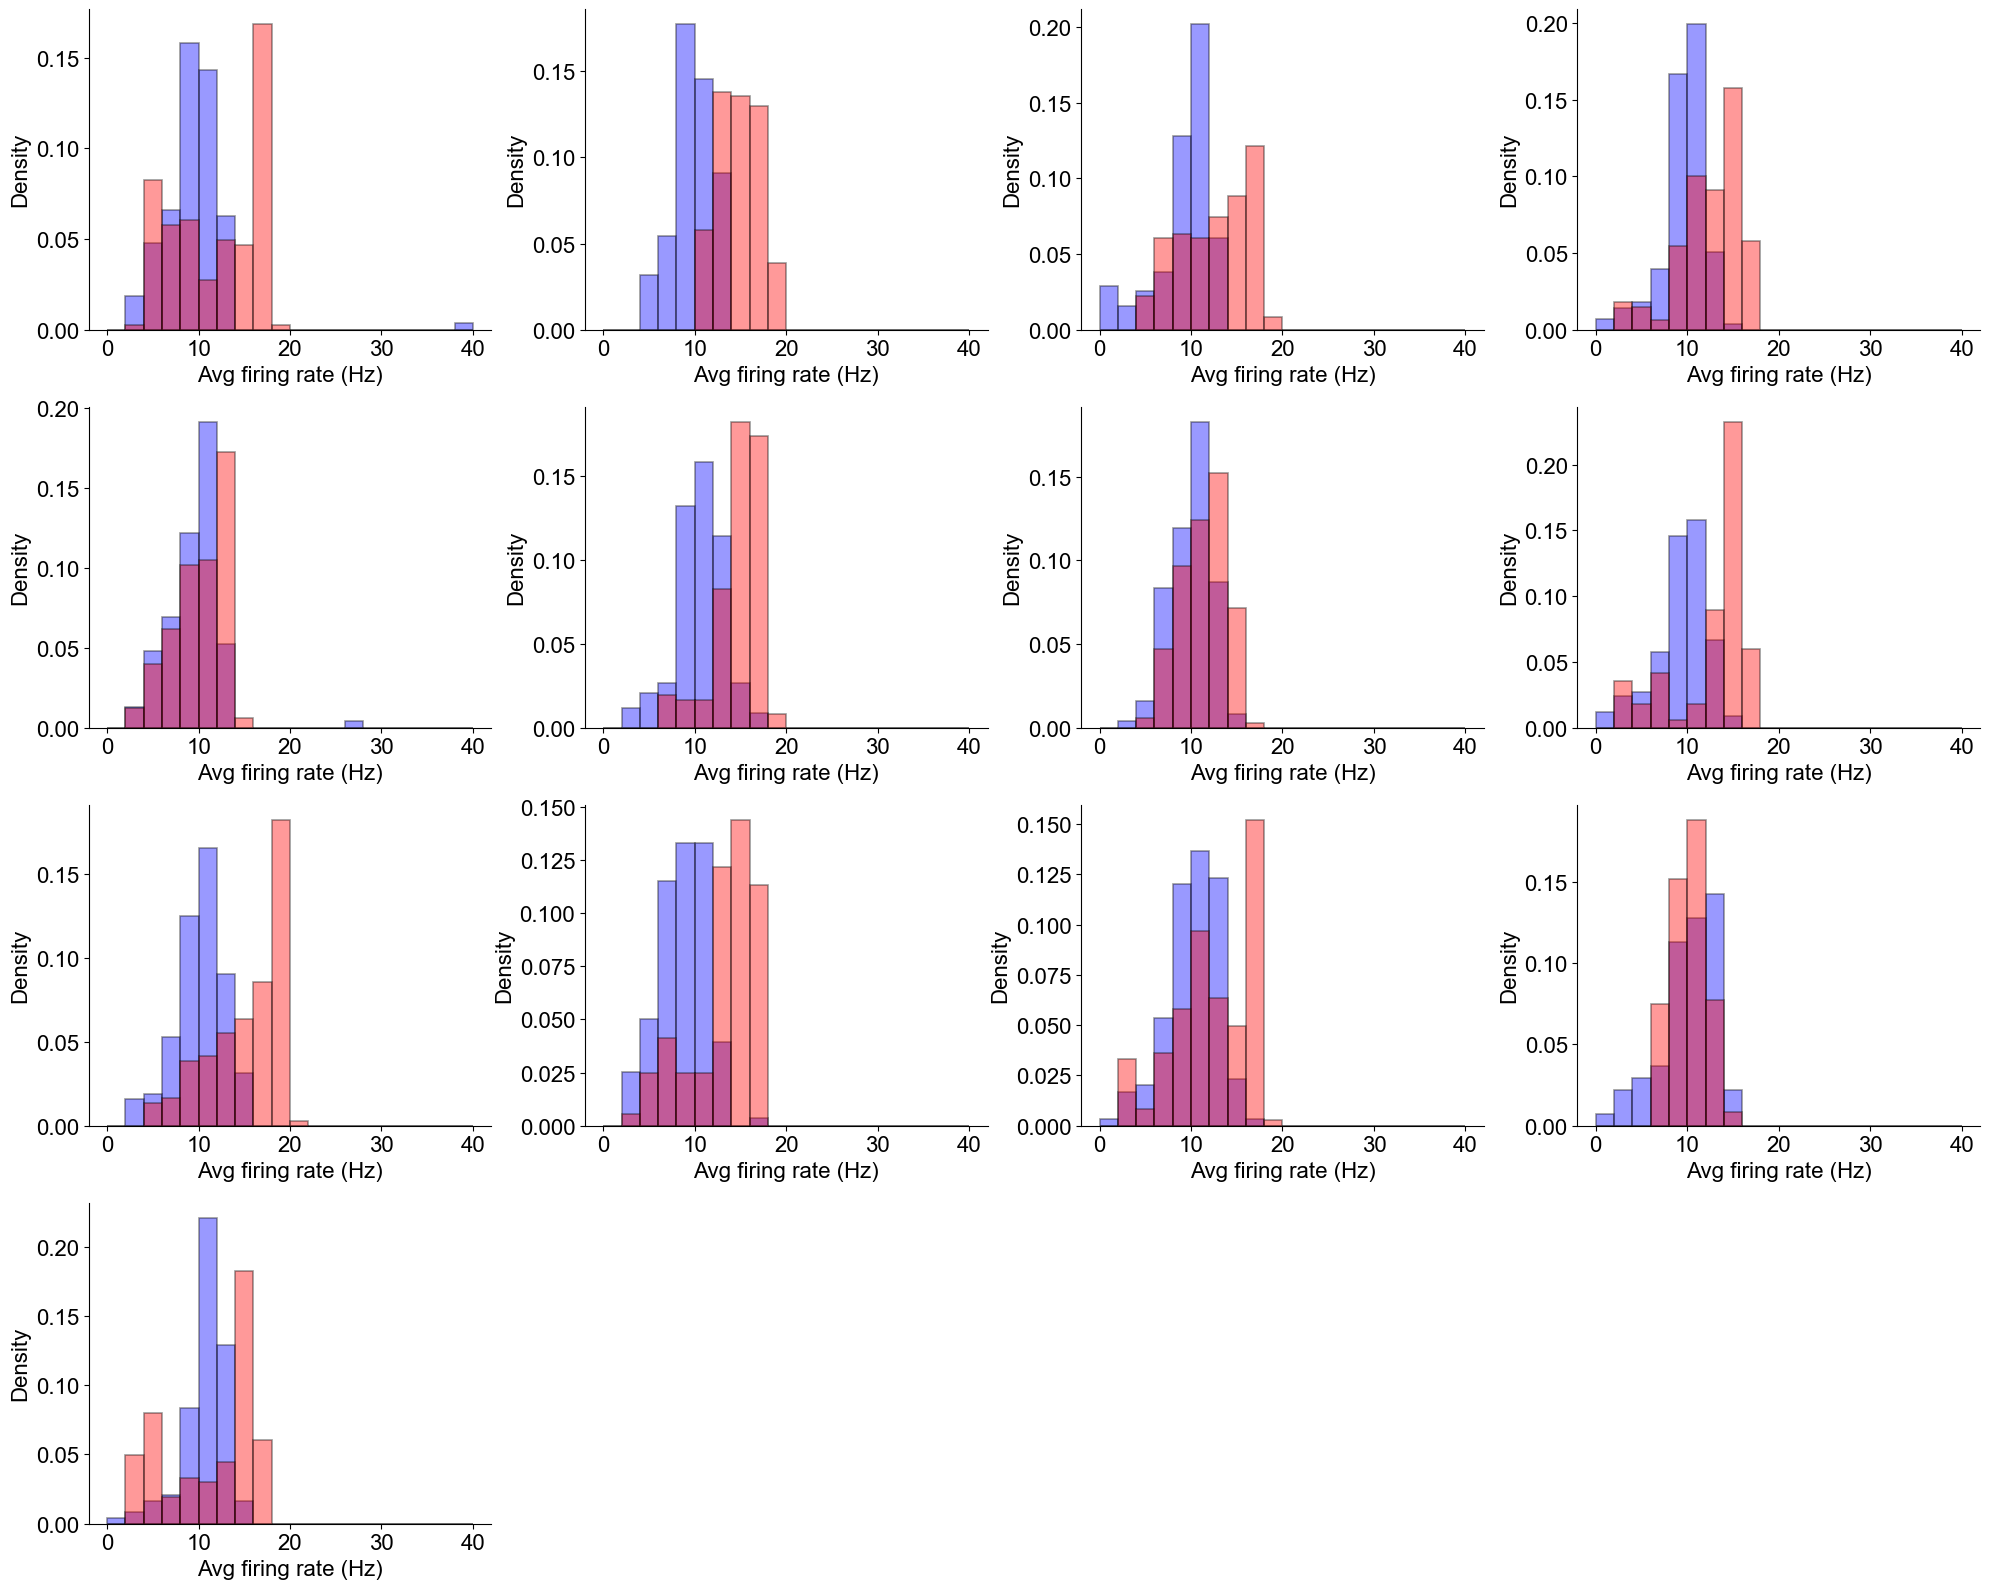

In [72]:
import os
import re
import pickle
import h5py
import numpy as np
import matplotlib.pyplot as plt



def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return int(match.group(1)[3:]) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_avg_firing_rate(spike_times, sampling_rate):
    if len(spike_times) < 2:
        return None
    ISIs = np.diff(spike_times) / sampling_rate
    return 1 / np.mean(ISIs)

def load_simulated_rates(jld2_file_paths):
    sim_rates_by_day = {}
    for path in jld2_file_paths:
        day_match = re.search(r'force(\d+)_firing_rates_rep_\.jld2', path)
        if not day_match:
            continue
        day = int(day_match.group(1))

        with h5py.File(path, 'r') as f:
            if 'avg_rates_per_neuron' in f:
                rates = f['avg_rates_per_neuron'][:]
                sim_rates_by_day[day] = rates
                print(sim_rates_by_day[day])
            else:
                print(f"'avg_rates_per_neuron' not found in {path}")
    return sim_rates_by_day

def compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths):
    sim_data = load_simulated_rates(jld2_file_paths)
    pkl_files = sorted(
        [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
        key=lambda x: (extract_day(x), extract_trial(x))
    )
    day_files = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            day_files.setdefault(day, []).append(file)

    n_days = len(day_files)
    n_cols = 4
    n_rows = int(np.ceil(n_days / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, (day, files) in enumerate(sorted(day_files.items())):
        all_firing_rates = []
        for file in files:
            with open(os.path.join(folder_path, file), 'rb') as f:
                data = pickle.load(f)
            MU_array = np.array(data['MU'])

            for neuron_idx in range(MU_array.shape[0]):
                spike_times = np.where(MU_array[neuron_idx] == 1)[0]
                fr = compute_avg_firing_rate(spike_times, Fsamp)
                if fr is not None and fr <= 80:
                    all_firing_rates.append(fr)

        ax = axes[i]
        bin_edges = np.linspace(0, 40, 21)

        ax.hist(all_firing_rates, bins=bin_edges, color='blue', alpha=0.4,
                label='Experimental', density=True, edgecolor='black', linewidth=1.2)

        if day in sim_data:
            ax.hist(sim_data[day], bins=bin_edges, color='red', alpha=0.4,
                    label='Simulated', density=True, edgecolor='black', linewidth=1.2)

        # ax.set_title(f'Day {day}: {len(all_firing_rates)} neurons')  # Title removed
        ax.set_xlabel('Avg firing rate (Hz)', fontsize=16)
        ax.set_ylabel('Density', fontsize=16)

        # Remove legend
        # ax.legend()

        # Remove top and right spines
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

        # Make ticks bigger
        ax.tick_params(axis='both', which='major', labelsize=16)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    return fig



folder_path = "/Users/nmt121/Desktop/DATA/S1"
Fsamp = 2048

jld2_file_paths = [
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_last_trial.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_last_trial.jld2',
    
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates_rep_.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_rep_.jld2',


    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force13_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force2_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force14_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force7_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force13_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force14_firing_rates.jld2',
    
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force1_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force3_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force4_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force5_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force8_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force9_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force10_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force11_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force12_firing_rates.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force13_firing_rates.jld2', 
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force14_firing_rates.jld2',
    
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force1_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force2_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force3_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force4_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force5_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force6_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force7_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force8_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force9_firing_rates7.jld2',
    # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force10_firing_rates7.jld2',




]

fig = compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths)
plt.savefig('/Users/nmt121/Desktop/Figures/FRdistributions_S1.pdf', dpi=300, bbox_inches='tight')
plt.show()



In [23]:
# save_forces_to_npy.py
import os, re, sys, pickle, json
import numpy as np
from collections import defaultdict

# ---------- helpers ----------
def extract_day(filename: str):
    m = re.search(r"(Day\d{2})", filename)
    return m.group(1) if m else ""

def extract_trial(filename: str):
    m = re.search(r'_(\d+)\D', filename)
    return int(m.group(1)) if m else 0

def to_1d_force(obj):
    """Robustly flatten Force to 1D float array."""
    try:
        x = np.array(obj).squeeze()
        if x.ndim > 1:
            x = np.array(obj.tolist())[0].squeeze()
    except Exception:
        x = np.array(obj.tolist())[0].squeeze()
    return np.asarray(x, float)

# ---------- main ----------
def save_all_forces_as_npy(input_dir: str, output_dir: str):
    os.makedirs(output_dir, exist_ok=True)

    manifest_rows = ["filename_npy,day,trial,length"]
    pkls = sorted([f for f in os.listdir(input_dir) if f.endswith(".pkl")])

    trials_by_day = defaultdict(list)

    for fn in pkls:
        in_path = os.path.join(input_dir, fn)
        with open(in_path, "rb") as f:
            data = pickle.load(f)

        force = to_1d_force(data["Force"])
        base = os.path.splitext(fn)[0]
        out_name = f"{base}_force.npy"
        out_path = os.path.join(output_dir, out_name)
        np.save(out_path, force)

        day = extract_day(fn)
        trial = extract_trial(fn)
        trials_by_day[day].append(trial)

        manifest_rows.append(f"{out_name},{day},{trial},{force.size}")
        print(f"Saved {out_name}  (len={force.size}, day={day}, trial={trial})")


    # Sort trials per day and save as npy + json
    trials_by_day_sorted = {day: sorted(nums) for day, nums in trials_by_day.items()}
    np.save(os.path.join(output_dir, "trials_by_day.npy"), trials_by_day_sorted)

    print("Saved trials_by_day.npy and trials_by_day.json")


    # Usage:
    #   python save_forces_to_npy.py /path/to/S1 /path/to/output
in_dir =  "/Users/nmt121/Desktop/DATA/S1"
out_dir = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Force_profiles"

save_all_forces_as_npy(in_dir, out_dir)



Saved E3_MB01_Day01High_1_force.npy  (len=43264, day=Day01, trial=1)
Saved E3_MB01_Day01High_11_force.npy  (len=43520, day=Day01, trial=11)
Saved E3_MB01_Day01High_14_force.npy  (len=43520, day=Day01, trial=14)
Saved E3_MB01_Day01High_17_force.npy  (len=14080, day=Day01, trial=17)
Saved E3_MB01_Day01High_21_force.npy  (len=43264, day=Day01, trial=21)
Saved E3_MB01_Day01High_24_force.npy  (len=28672, day=Day01, trial=24)
Saved E3_MB01_Day01High_27_force.npy  (len=43520, day=Day01, trial=27)
Saved E3_MB01_Day01High_30_force.npy  (len=32512, day=Day01, trial=30)
Saved E3_MB01_Day01High_6_force.npy  (len=43520, day=Day01, trial=6)
Saved E3_MB01_Day01High_9_force.npy  (len=14592, day=Day01, trial=9)
Saved E3_MB01_Day03High_11_force.npy  (len=43520, day=Day03, trial=11)
Saved E3_MB01_Day03High_14_force.npy  (len=37632, day=Day03, trial=14)
Saved E3_MB01_Day03High_18_force.npy  (len=27392, day=Day03, trial=18)
Saved E3_MB01_Day03High_21_force.npy  (len=36864, day=Day03, trial=21)
Saved E3_MB0

In [26]:
# make_exp_avg_rates.py
import os, re, sys, pickle, numpy as np

def extract_day(filename):
    m = re.search(r"(Day\d{2})", filename)
    return int(m.group(1)[3:]) if m else None

def extract_trial(filename):
    m = re.search(r'_(\d+)[^0-9]', filename)
    return int(m.group(1)) if m else 0

def compute_avg_firing_rate(spike_times, sampling_rate):
    if len(spike_times) < 2:
        return None
    ISIs = np.diff(spike_times) / sampling_rate
    return 1 / np.mean(ISIs)

def main(folder_path, out_dir, Fsamp=2048, max_rate=80.0):
    os.makedirs(out_dir, exist_ok=True)
    pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith(".pkl")],
                       key=lambda x: (extract_day(x) or 0, extract_trial(x)))
    for fn in pkl_files:
        day = extract_day(fn)
        trial = extract_trial(fn)
        if day is None:
            continue
        with open(os.path.join(folder_path, fn), "rb") as f:
            data = pickle.load(f)

        MU_array = np.array(data["MU"])  # shape: MUs x Samples, binary
        rates = []
        for neuron_idx in range(MU_array.shape[0]):
            spike_times = np.where(MU_array[neuron_idx] == 1)[0]
            fr = compute_avg_firing_rate(spike_times, Fsamp)
            if fr is not None and fr <= max_rate:
                rates.append(fr)

        rates = np.array(rates, float)
        out_name = f"EXP_Day{day:02d}_trial{trial:02d}_avg_rates.npy"
        np.save(os.path.join(out_dir, out_name), rates)
        print(f"Saved {out_name}  (n={rates.size})")

in_dir =  "/Users/nmt121/Desktop/DATA/S1"
out_dir = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Frs"
Fsamp   = int(sys.argv[3]) if len(sys.argv) > 3 else 2048
main(in_dir, out_dir, Fsamp)


Saved EXP_Day01_trial01_avg_rates.npy  (n=15)
Saved EXP_Day01_trial06_avg_rates.npy  (n=15)
Saved EXP_Day01_trial09_avg_rates.npy  (n=15)
Saved EXP_Day01_trial11_avg_rates.npy  (n=15)
Saved EXP_Day01_trial14_avg_rates.npy  (n=15)
Saved EXP_Day01_trial17_avg_rates.npy  (n=15)
Saved EXP_Day01_trial21_avg_rates.npy  (n=15)
Saved EXP_Day01_trial24_avg_rates.npy  (n=11)
Saved EXP_Day01_trial27_avg_rates.npy  (n=15)
Saved EXP_Day01_trial30_avg_rates.npy  (n=15)
Saved EXP_Day03_trial03_avg_rates.npy  (n=11)
Saved EXP_Day03_trial04_avg_rates.npy  (n=11)
Saved EXP_Day03_trial09_avg_rates.npy  (n=11)
Saved EXP_Day03_trial11_avg_rates.npy  (n=11)
Saved EXP_Day03_trial14_avg_rates.npy  (n=11)
Saved EXP_Day03_trial18_avg_rates.npy  (n=11)
Saved EXP_Day03_trial21_avg_rates.npy  (n=11)
Saved EXP_Day03_trial23_avg_rates.npy  (n=11)
Saved EXP_Day03_trial26_avg_rates.npy  (n=11)
Saved EXP_Day03_trial29_avg_rates.npy  (n=11)
Saved EXP_Day04_trial01_avg_rates.npy  (n=15)
Saved EXP_Day04_trial06_avg_rates.

## Get rasters for each of the trials

In [ ]:
from functions_analysis_online_control_exp.create_rasters import *
# fig = create_raster('/Users/nmt121/Desktop/DATA/S7/', Fsamp=1000, extract_day=extract_day, extract_trial=extract_trial)
# plt.show(fig)
# # fig.savefig('/Users/nmt121/Desktop/trial_plot.pdf', dpi=300, bbox_inches='tight')

# Behavioral analysis

## Plot force trajectories for every day and every trial

In [ ]:
from functions_analysis_online_control_exp.force_trajectories import *
# fsamp = 2048  
# highlight_samples = int(3 * fsamp)  #in case one wants to highlight part of the trajectory
# fig = create_force_plots_by_day(directory_path='/Users/nmt121/Desktop/DATA/S1/',fsamp=2048,highlight_samples=1000,extract_day=extract_day,extract_trial=extract_trial)
# plt.show(fig)
# # # plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')

### Plot force trajectories from 2 first and 2 last days 

In [19]:
from functions_analysis_online_control_exp.force_trajectories import *
# plot_force_trials(directory_path="/Users/nmt121/Desktop/DATA/S7",output_path="/Users/nmt121/Desktop/Figures/S7force.pdf")

## Measure smoothness of the force signal 

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/functions_analysis_online_control_exp/smoothness_force_signal.py:74: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/functions_analysis_online_control_exp/smoothness_force_signal.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


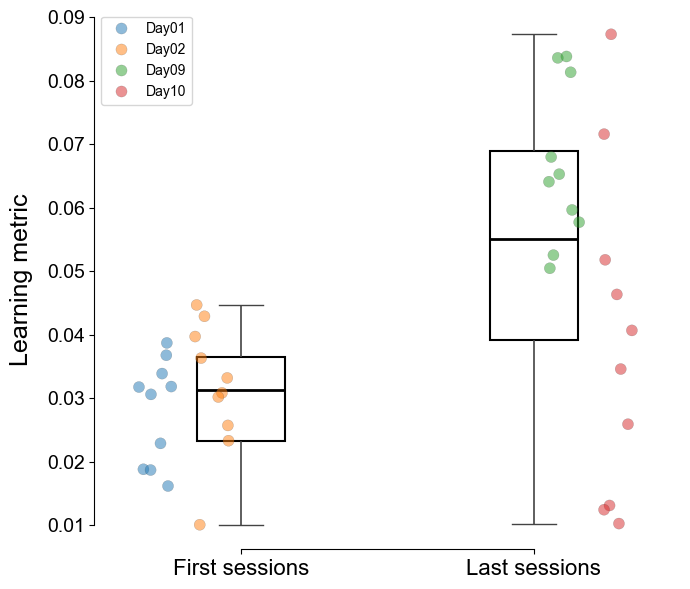

In [16]:
from functions_analysis_online_control_exp.smoothness_force_signal import *

fig = compute_signal_smoothness('/Users/nmt121/Desktop/DATA/S7/', fsamp=2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/learningmetric7_amplitudefft.pdf", dpi=300, bbox_inches='tight')

## Success rate

In [7]:
from functions_analysis_online_control_exp.success_rate import *

results = trial_success_rate_per_day('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048)

for day, stats in results.items():
    print(f"{day}: {stats['success_rate']:.1f}% ({stats['n_success']}/{stats['n_total']})")



Day01: 40.0% (4/10)
Day03: 50.0% (5/10)
Day04: 90.9% (10/11)
Day05: 100.0% (10/10)
Day06: 100.0% (10/10)
Day07: 90.0% (9/10)
Day08: 100.0% (9/9)
Day09: 100.0% (10/10)
Day10: 50.0% (5/10)
Day11: 100.0% (10/10)
Day12: 20.0% (2/10)
Day13: 100.0% (10/10)
Day14: 100.0% (10/10)


### Stats for differences in success between first two and last two days

In [ ]:
day1 = [40,20,10,0,0,0]
day2 = [50,60,100,30,70,20]
day13 = [10,90,100,30,80,52.9]
day14 = [100,70,100,66.7,70,10]

first_sessions = np.array(day1 + day2)
last_sessions  = np.array(day13 + day14)

print("First sessions mean ± std: %.2f ± %.2f" % (np.mean(first_sessions), np.std(first_sessions)))
print("Last sessions mean ± std:  %.2f ± %.2f" % (np.mean(last_sessions), np.std(last_sessions)))

# Independent samples t-test (Welch's)
t_stat, p_val = stats.ttest_ind(first_sessions, last_sessions, equal_var=False)
print("Welch t-test: t = %.3f, p = %.4f" % (t_stat, p_val))

# Mann-Whitney U test (nonparametric alternative)
u_stat, p_u = stats.mannwhitneyu(first_sessions, last_sessions, alternative="two-sided")
print("Mann–Whitney U: U = %.3f, p = %.4f" % (u_stat, p_u))


First sessions mean ± std: 33.33 ± 30.37
Last sessions mean ± std:  64.97 ± 31.62
Welch t-test: t = -2.393, p = 0.0257
Mann–Whitney U: U = 34.000, p = 0.0295


## Take most representative trial

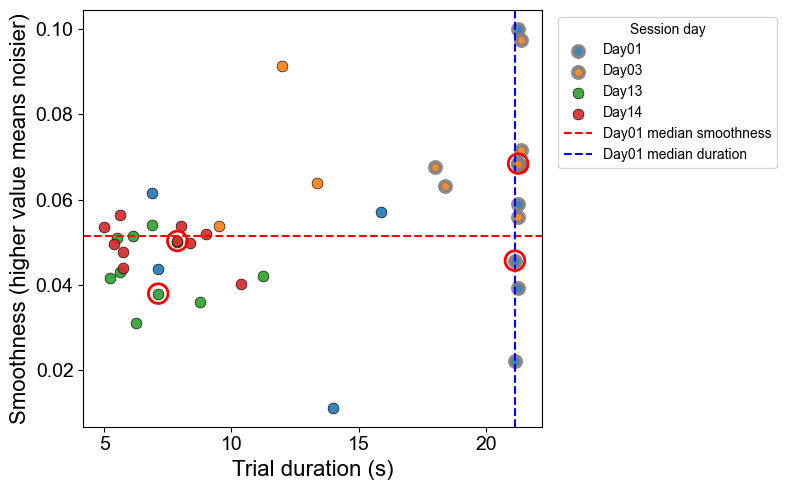

       Day  Trial                      File  TrialDur_s  Smoothness
6    Day01     21  E3_MB01_Day01High_21.pkl      21.125    0.045720
13   Day03     11  E3_MB01_Day03High_11.pkl      21.250    0.068481
22   Day04      9   E3_MB01_Day04High_9.pkl       7.875    0.051828
36   Day05     18  E3_MB01_Day05High_18.pkl       6.000    0.080721
42   Day06      5   E3_MB01_Day06High_5.pkl       8.750    0.034478
57   Day07     19  E3_MB01_Day07High_19.pkl      10.750    0.063988
67   Day08     23  E3_MB01_Day08High_23.pkl      10.750    0.044008
73   Day09      9   E3_MB01_Day09High_9.pkl       8.875    0.040275
84   Day10     15  E3_MB01_Day10High_15.pkl      18.875    0.059173
92   Day11      8   E3_MB01_Day11High_8.pkl       6.000    0.062577
108  Day12     25  E3_MB01_Day12High_25.pkl      21.375    0.062187
112  Day13      9   E3_MB01_Day13High_9.pkl       7.125    0.037995
129  Day14     28  E3_MB01_Day14High_28.pkl       7.875    0.050339


In [ ]:
from functions_analysis_online_control_exp.choose_representative_force_trial import *


df, selected = duration_vs_smoothness_scatter_with_median(
    '/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, high_freq_threshold=5.0,
    keep_first_last=True, annotate=True,
    save_path="/Users/nmt121/Desktop/Figures/dur_vs_smoothness_S7.pdf"
)


## Compute FFT to see frequency content 

In [ ]:
from functions_analysis_online_control_exp/.FFT_function import *
# results = plot_fft_and_compute_metric_per_trial('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, fmin=10.0, max_freq=30)


## Plot firing rate state space (in this case for two first and last 2 sessions)

In [ ]:
from functions_analysis_online_control_exp.plot_fr_trajectories import *
# plot_fr_trajectories(directory_path="/Users/nmt121/Desktop/DATA/S1",output_path="/Users/nmt121/Desktop/S7_FR_trajectory.pdf",clip_thresh=35)

## Plot peak count for each day

In [18]:
from functions_analysis_online_control_exp.count_peaks_smoothnes import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# fig = create_peak_count_summary(directory_paths=directory_paths,fsamp=2048,extract_day=extract_day,extract_trial=extract_trial,lowpass_filter=lowpass_filter)

# Save when ready
# fig.savefig("/Users/nmt121/Desktop/Figures/peaks_summary.pdf", dpi=300, bbox_inches='tight')

# Or display when ready
# plt.show(fig)


## Plot trial duration for all trials

In [ ]:
from functions_analysis_online_control_exp.trial_duration import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# plot_avg_trial_durations(directory_paths, fsamp=2048,save_path="/Users/nmt121/Desktop/Figures/avg_trial_durations.pdf")


### Plot trial durations from 2 first and 2 last days 

In [ ]:
from functions_analysis_online_control_exp.trial_duration import *

# fig = plot_first_last_two_days_duration_box('/Users/nmt121/Desktop/DATA/S1/', 2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/trial_duration_session1.pdf", dpi=300, bbox_inches='tight')
# run_duration_stats('/Users/nmt121/Desktop/DATA/S7/', 2048)


## Plot decorrelation time (for how long the higher threshold motoneuron fires alone)

In [75]:
# from functions_experimental_data_Bräckleinexp.decorrelation_time import *
# plot_prolonged_firing_duration(directory_path="/Users/nmt121/Desktop/DATA/S1",fsamp=2048
#     # scatter_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_scatter.pdf",
#     # trend_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_trend.pdf"
# )


## FIRING RATES

In [3]:
def spikes_to_firing_rate(spike_array, fs, window_duration=0.3):
    
    n_units, T = spike_array.shape
    wlen = int(round(window_duration * fs))
    wlen = max(3, wlen + (wlen % 2 == 0))  # prefer odd length >=3
    h = windows.hann(wlen)
    h /= h.sum()
    fr = np.empty_like(spike_array, dtype=float)
    for i in range(n_units):
        fr[i] = convolve(spike_array[i], h, mode='same') * fs
    return fr

### FR experimental data

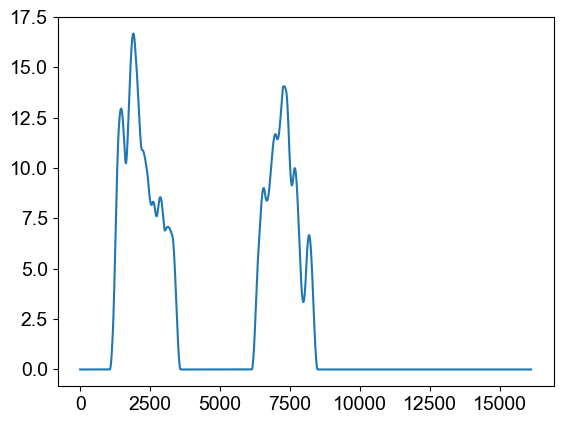

In [76]:

file_path = "/Users/nmt121/Desktop/DATA/S1/E3_MB01_Day14High_28.pkl"



with open(file_path, "rb") as f:
    data = pickle.load(f)

spike_array = data["MU"]  
fs = 2048  
fr_exp = spikes_to_firing_rate(spike_array, fs, window_duration=0.3)
fr_exp.T.shape
plt.plot(fr_exp[0,:])

In [65]:
data["Idx_MU_Pair"]  


array([9, 3], dtype=uint8)

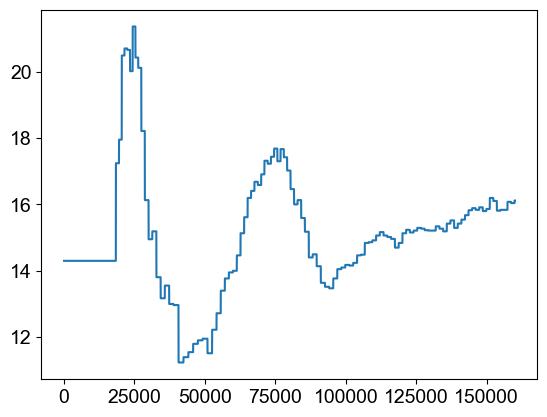

In [80]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/all_rates_full14.jld2" 
with h5py.File(file_path, "r") as f:
    fr_sim = f["rates_full"][:]  

fr_sim.shape
plt.plot(fr_sim[:,3])

In [69]:
# downsample simulation to experimental length
target_len = fr_exp.shape[1]
fr_sim_resampled = resample(fr_sim.T, target_len, axis=1)
print(fr_sim_resampled.shape)  # (181, 43264)

(181, 43264)


In [70]:
n_exp, T = fr_exp.shape
n_sim, _ = fr_sim_resampled.shape

corr_matrix = np.zeros((n_exp, n_sim))
for i in range(n_exp):
    for j in range(n_sim):
        corr_matrix[i, j] = pearsonr(fr_exp[i], fr_sim_resampled[j])[0]



Experimental neuron 0 ↔ Simulated neuron 66 | r = 0.249
Experimental neuron 1 ↔ Simulated neuron 27 | r = 0.697
Experimental neuron 2 ↔ Simulated neuron 55 | r = 0.363
Experimental neuron 3 ↔ Simulated neuron 23 | r = 0.490
Experimental neuron 4 ↔ Simulated neuron 66 | r = 0.341
Experimental neuron 5 ↔ Simulated neuron 27 | r = 0.685
Experimental neuron 6 ↔ Simulated neuron 55 | r = 0.420
Experimental neuron 7 ↔ Simulated neuron 50 | r = 0.682
Experimental neuron 8 ↔ Simulated neuron 68 | r = 0.436
Experimental neuron 9 ↔ Simulated neuron 51 | r = 0.536
Experimental neuron 10 ↔ Simulated neuron 55 | r = 0.271
Experimental neuron 11 ↔ Simulated neuron 66 | r = 0.357
Experimental neuron 12 ↔ Simulated neuron 66 | r = 0.433
Experimental neuron 13 ↔ Simulated neuron 27 | r = 0.335
Experimental neuron 14 ↔ Simulated neuron 55 | r = 0.389


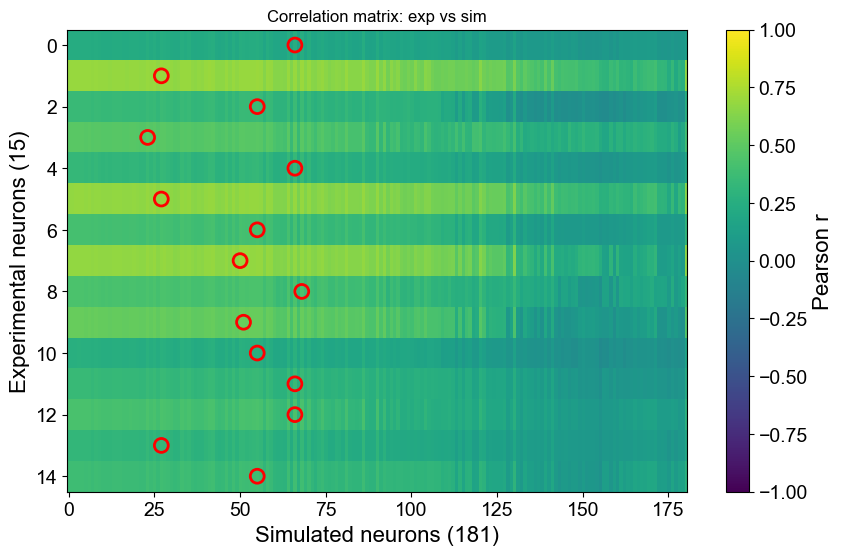

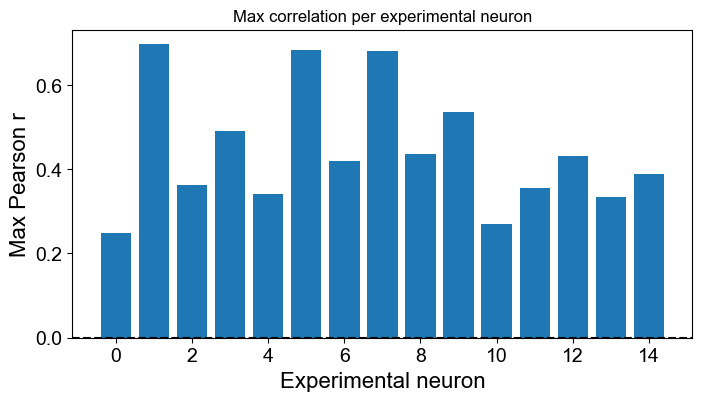

In [71]:
# 1. Compute max per row
max_vals = corr_matrix.max(axis=1)   # length = 15
best_match = corr_matrix.argmax(axis=1)  # index of best simulated neuron per row

# Print matches
for exp_idx, (sim_idx, corr) in enumerate(zip(best_match, max_vals)):
    print(f"Experimental neuron {exp_idx} ↔ Simulated neuron {sim_idx} | r = {corr:.3f}")

# 2. Plot the heatmap + red markers
plt.figure(figsize=(10,6))
im = plt.imshow(corr_matrix, aspect='auto', cmap='viridis', vmin=-1, vmax=1)
# im.savefig("/Users/nmt121/Desktop/corr.pdf", dpi=300, bbox_inches='tight')

plt.colorbar(im, label="Pearson r")
plt.xlabel("Simulated neurons (181)")
plt.ylabel("Experimental neurons (15)")
plt.title("Correlation matrix: exp vs sim")

# add red circle markers on maxima
for exp_idx, sim_idx in enumerate(best_match):
    plt.scatter(sim_idx, exp_idx, s=100, facecolors='none', edgecolors='red', linewidths=2)
fig.savefig("/Users/nmt121/Desktop/Figures/corr_maxvals_day1.pdf", dpi=300, bbox_inches='tight')

plt.show()

# 3. Plot the max values per row as a bar plot
plt.figure(figsize=(8,4))
plt.bar(np.arange(len(max_vals)), max_vals, color="C0")
plt.axhline(0, color='k', linestyle='--')
plt.ylabel("Max Pearson r")
plt.xlabel("Experimental neuron")
plt.title("Max correlation per experimental neuron")
fig.savefig("/Users/nmt121/Desktop/Figures/corr_maxvals_day1.pdf", dpi=300, bbox_inches='tight')
plt.show()